In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
plt.rcParams['font.sans-serif'] = ['SimHei']  
plt.rcParams['axes.unicode_minus'] = False 

In [3]:
data=pd.read_csv('Phishing_Email.csv')
data.head()

,Unnamed: 0,Email Text,Email Type
0,0,"re : 6 . 1100 , disc : uniformitarianism , re ...",Safe Email
1,1,the other side of * galicismos * * galicismo *...,Safe Email
2,2,re : equistar deal tickets are you still avail...,Safe Email
3,3,\nHello I am your hot lil horny toy.\n I am...,Phishing Email
4,4,software at incredibly low prices ( 86 % lower...,Phishing Email


C:\Users\huawei\AppData\Local\Temp\ipykernel_28688\2271209510.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


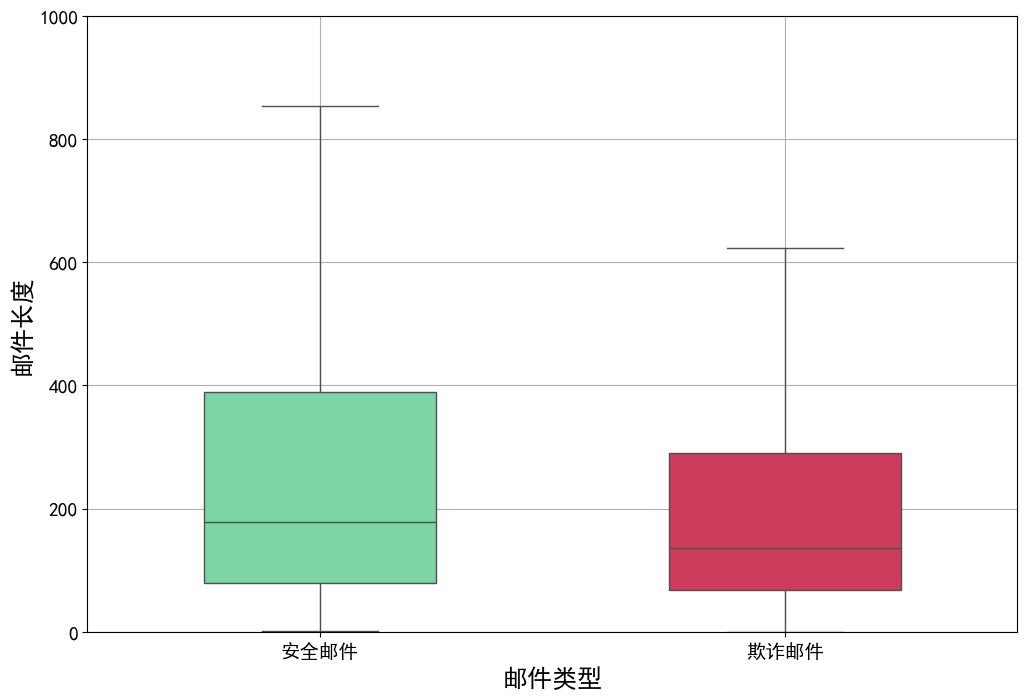

In [5]:
data['Word_Count'] = data['Email Text'].fillna('').astype(str).apply(lambda x: len(x.split()))

plt.figure(figsize=(12, 8))
sns.boxplot(
    data=data,  
    x='Email Type',
    y='Word_Count',
    width=0.5,
    showfliers=False,
    palette = ["#6DE4A4", "#E6244E"]  
)

plt.xlabel('邮件类型',fontsize=18)
plt.ylabel('邮件长度',fontsize=18)
plt.xticks(ticks=['Safe Email', 'Phishing Email'], labels=['安全邮件', '欺诈邮件'],fontsize=14)
plt.yticks(fontsize=14)
plt.ylim(0, 1000)  
plt.grid(True)
plt.savefig('Boxplot.png')
plt.show()

C:\Users\huawei\AppData\Local\Temp\ipykernel_28688\4274420082.py:10: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.histplot(


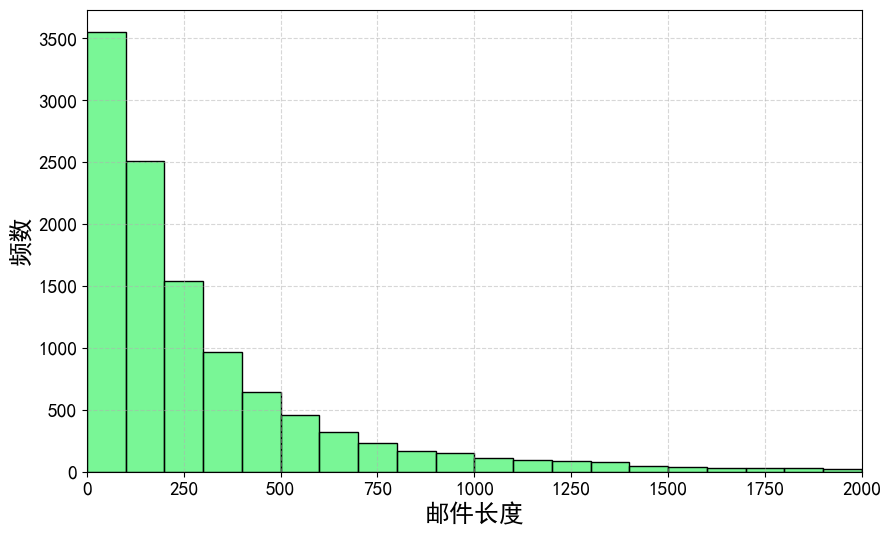

In [6]:
data['Word_Count'] = pd.to_numeric(data['Word_Count'], errors='coerce')
data.dropna(subset=['Word_Count'], inplace=True)

email_types = data['Email Type'].unique()
bin = np.arange(0, 5000, 100)

subset_data = data[data['Email Type'] == 'Safe Email']
    
plt.figure(figsize=(10, 6))
sns.histplot(
    data=subset_data,
    x='Word_Count',
    bins=bin,
    color="#20F050",
    palette='Black',
    alpha=0.6,
    kde=False,
    stat='count',
    fill=True
)

plt.xlabel('邮件长度',fontsize=18)
plt.ylabel('频数',fontsize=18)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.xlim(0, 2000)
plt.grid(True, linestyle='--', alpha=0.5)
plt.savefig('Safe_Histogram.png')
plt.show()

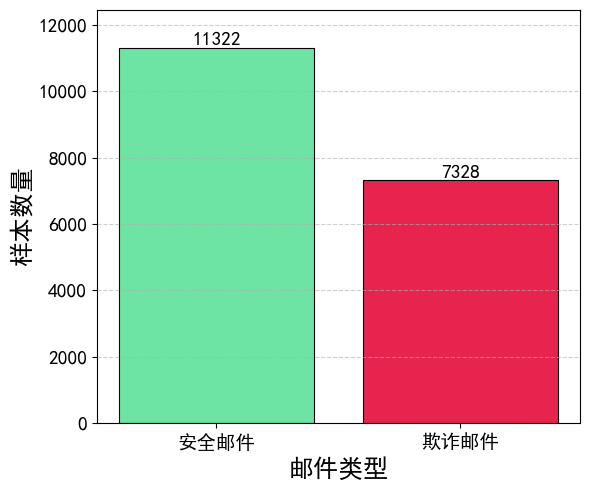

In [10]:
email_counts = data['Email Type'].value_counts()

email_counts.index = email_counts.index.map({
    'Safe Email': '安全邮件',
    'Phishing Email': '欺诈邮件'
})


plt.figure(figsize=(6, 5))
bars = plt.bar(email_counts.index, email_counts.values, 
               color=["#6DE4A4", "#E6244E"],  
               edgecolor='black', linewidth=0.8)

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, height + 10, 
             f'{int(height)}', ha='center', va='bottom', fontsize=14)

plt.xlabel('邮件类型', fontsize=18)
plt.ylabel('样本数量', fontsize=18)
plt.ylim(0, email_counts.max() * 1.1) 
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig('Email_Count_Comparison.png')
plt.show()